# 04 · Local explanations
Why does the model flag *this* person? Three tools:
1. **SHAP** waterfall plots for three contrasting cases (a caught case, a missed case, a false alarm).
2. **LIME** on the same cases, and an agreement study with SHAP over 100 people.
3. **Counterfactuals**: what minimal, *actionable* change would move a flagged person below the screening threshold.

Operating point from notebook 02: LightGBM with threshold chosen for recall ≥ 80 % on validation.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib, shap, warnings
from scipy.stats import spearmanr
from lime.lime_tabular import LimeTabularExplainer
from src.preprocess import get_splits
from src.evaluation import threshold_for_recall
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
X_tr, X_va, X_te, y_tr, y_va, y_te = get_splits()
gbm = joblib.load("../models/lightgbm.joblib")
feats = list(X_tr.columns)
thr = threshold_for_recall(y_va, gbm.predict_proba(X_va)[:,1], 0.80)
p_te = gbm.predict_proba(X_te)[:,1]
print(f"screening threshold = {thr:.3f}")

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


screening threshold = 0.148


## 1. Three contrasting cases
Chosen deterministically from the test set: (A) a diabetic person the model flags with high confidence, (B) a diabetic person the model **misses**, (C) a healthy person that is flagged (false alarm).

In [2]:
idxA = int(np.argmin(np.where(y_te.values == 1, np.abs(p_te - 0.60), 9)))
idxB = int(np.argmin(np.where(y_te.values == 1, np.abs(p_te - 0.07), 9)))
idxC = int(np.argmin(np.where(y_te.values == 0, np.abs(p_te - 0.45), 9)))
cases = {"A · true positive": idxA, "B · missed case (false negative)": idxB, "C · false alarm (false positive)": idxC}
for k, i in cases.items():
    print(f"{k:34s} p={p_te[i]:.3f}  true label={y_te.iloc[i]}  flagged={p_te[i] >= thr}")
pd.DataFrame({k: X_te.iloc[i] for k, i in cases.items()})

A · true positive                  p=0.600  true label=1  flagged=True
B · missed case (false negative)   p=0.070  true label=1  flagged=False
C · false alarm (false positive)   p=0.450  true label=0  flagged=True


,A · true positive,B · missed case (false negative),C · false alarm (false positive)
HighBP,1,0,1
HighChol,1,0,1
CholCheck,1,1,1
BMI,41,30,37
Smoker,1,1,0
Stroke,0,0,0
HeartDiseaseorAttack,0,0,0
PhysActivity,0,0,1
Fruits,1,1,0
Veggies,0,0,1


### SHAP waterfall
Each bar = contribution (log-odds) of a feature to this person's prediction relative to the average prediction; they add up to the final score.

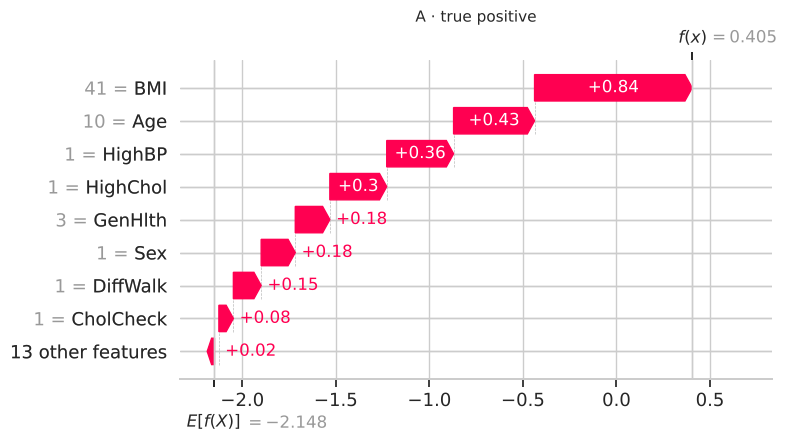

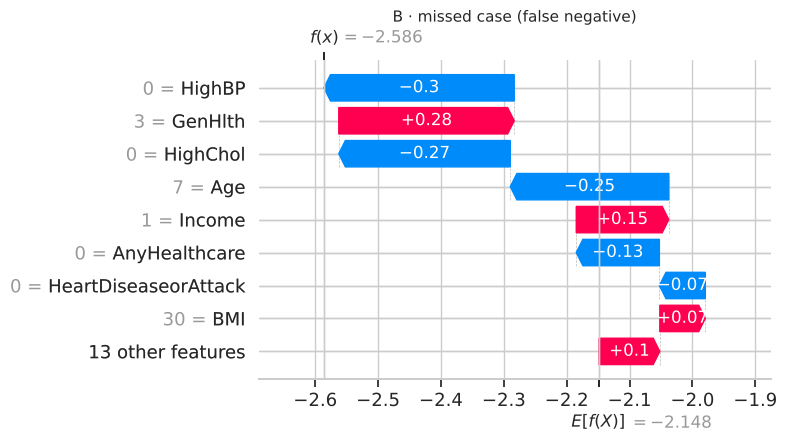

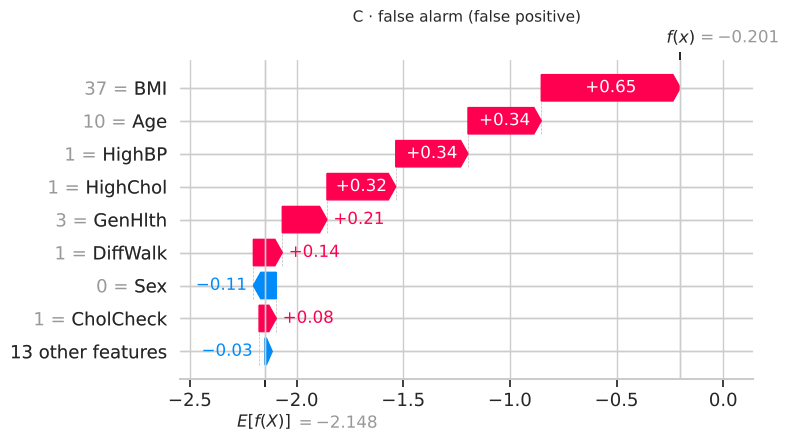

In [3]:
expl = shap.TreeExplainer(gbm, data=X_tr.sample(100, random_state=0), feature_perturbation="interventional", model_output="raw")
sv_cases = {k: expl(X_te.iloc[[i]])[0] for k, i in cases.items()}
for k, sv in sv_cases.items():
    plt.figure(); shap.plots.waterfall(sv, max_display=9, show=False)
    plt.title(k, fontsize=11); plt.gcf().set_size_inches(8, 4.6); plt.tight_layout()
    plt.savefig(f"../figures/local_waterfall_{k[0]}.png", dpi=150, bbox_inches="tight"); plt.show()

## 2. LIME and agreement with SHAP
LIME fits a sparse linear model on perturbed copies of the person, weighted by proximity (explains the **probability**). Binary and ordinal features are treated as categorical, BMI / MentHlth / PhysHlth are discretised.

In [4]:
cat_idx = [i for i, f in enumerate(feats) if f not in ("BMI", "MentHlth", "PhysHlth")]
lime = LimeTabularExplainer(X_tr.to_numpy(), feature_names=feats, categorical_features=cat_idx,
                            class_names=["no diabetes", "diabetes"], discretize_continuous=True, random_state=0)
def lime_weights(x, seed=0, n=5000):
    lime.random_state = np.random.RandomState(seed)
    e = lime.explain_instance(x.to_numpy(), gbm.predict_proba, num_features=len(feats), num_samples=n, labels=(1,))
    w = dict(e.as_map()[1]); return np.array([w.get(j, 0.0) for j in range(len(feats))]), e.score
for k, i in cases.items():
    w, r2 = lime_weights(X_te.iloc[i])
    top = pd.Series(w, index=feats).reindex(pd.Series(w, index=feats).abs().sort_values(ascending=False).index).head(6)
    sh = pd.Series(sv_cases[k].values, index=feats); sh = sh.reindex(sh.abs().sort_values(ascending=False).index).head(6)
    print(f"--- {k}   (LIME local R² = {r2:.2f})")
    print(pd.DataFrame({"LIME top6": top.index, "LIME w": top.values.round(3), "SHAP top6": sh.index, "SHAP": sh.values.round(3)}).to_string(index=False))

--- A · true positive   (LIME local R² = 0.41)
        LIME top6  LIME w SHAP top6  SHAP
              BMI   0.115       BMI 0.842
        CholCheck   0.093       Age 0.433
           HighBP   0.069    HighBP 0.357
HvyAlcoholConsump   0.064  HighChol 0.304
         HighChol   0.055   GenHlth 0.185
              Age   0.050       Sex 0.182
--- B · missed case (false negative)   (LIME local R² = 0.23)
           LIME top6  LIME w     SHAP top6   SHAP
           CholCheck   0.085        HighBP -0.303
              HighBP  -0.067       GenHlth  0.279
   HvyAlcoholConsump   0.062      HighChol -0.273
            HighChol  -0.054           Age -0.252
HeartDiseaseorAttack  -0.038        Income  0.147
                 Sex   0.027 AnyHealthcare -0.132
--- C · false alarm (false positive)   (LIME local R² = 0.41)
        LIME top6  LIME w SHAP top6  SHAP
              BMI   0.115       BMI 0.652
        CholCheck   0.093       Age 0.344
           HighBP   0.069    HighBP 0.339
HvyAlcoholConsump

In [5]:
rng = np.random.default_rng(1)
sample = rng.choice(len(X_te), 100, replace=False)
sv100 = expl(X_te.iloc[sample]).values
rows = []
for j, i in enumerate(sample):
    w, r2 = lime_weights(X_te.iloc[i], seed=j)
    s = sv100[j]
    top5_l, top5_s = set(np.argsort(-np.abs(w))[:5]), set(np.argsort(-np.abs(s))[:5])
    top3_l, top3_s = set(np.argsort(-np.abs(w))[:3]), set(np.argsort(-np.abs(s))[:3])
    both = [f for f in range(len(feats)) if w[f] != 0 and s[f] != 0]
    rows.append({"jaccard_top5": len(top5_l & top5_s) / len(top5_l | top5_s), "same_top1": int(np.argmax(np.abs(w)) == np.argmax(np.abs(s))),
                 "jaccard_top3": len(top3_l & top3_s) / len(top3_l | top3_s),
                 "sign_agree_top5": np.mean([np.sign(w[f]) == np.sign(s[f]) for f in top5_s & top5_l]) if top5_s & top5_l else np.nan,
                 "spearman": spearmanr(np.abs(w), np.abs(s))[0], "lime_r2": r2})
ag = pd.DataFrame(rows)
ag.describe().loc[["mean", "std", "min", "50%"]].round(3)

,jaccard_top5,same_top1,jaccard_top3,sign_agree_top5,spearman,lime_r2
mean,0.468,0.220,0.406,1.0,0.743,0.339
std,0.138,0.416,0.197,0.0,0.073,0.073
min,0.111,0.000,0.000,1.0,0.556,0.215
50%,0.429,0.000,0.500,1.0,0.760,0.328


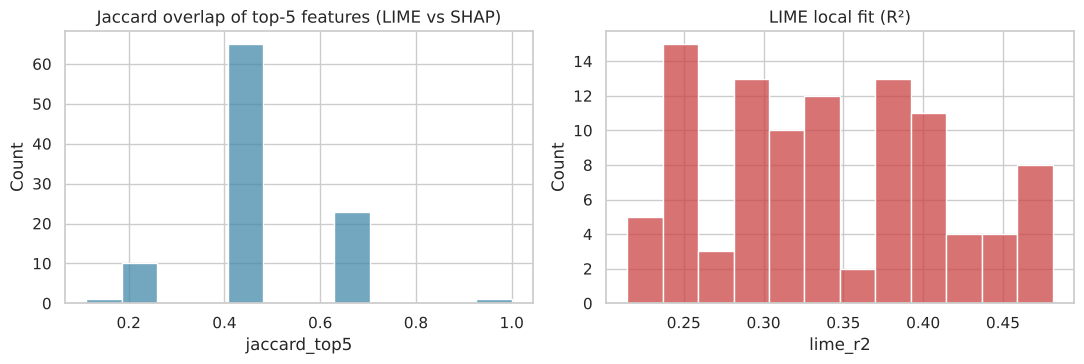

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(ag.jaccard_top5, bins=12, ax=axes[0], color="#48a"); axes[0].set_title("Jaccard overlap of top-5 features (LIME vs SHAP)")
sns.histplot(ag.lime_r2, bins=12, ax=axes[1], color="#c44"); axes[1].set_title("LIME local fit (R²)")
plt.tight_layout(); plt.savefig("../figures/local_lime_vs_shap.png", dpi=150); plt.show()

## 3. Counterfactual explanations
For people flagged at the screening threshold, we look for nearby profiles that would **not** be flagged.
We use our own exhaustive search (`src/counterfactuals.py`; the search space is tiny, and the DiCE library did not run with the installed pandas version), with the properties from the course:
- **Validity:** the real model predicts below the screening threshold.
- **Sparsity & proximity:** fewest changed features first, then smallest BMI change.
- **Feasibility:** only actionable features change, only in the healthy direction. Immutable: `Age`, `Sex`, `Education`, `Income`. Not actionable by the person: `GenHlth`, `PhysHlth`, `MentHlth`, `DiffWalk`, `Stroke`, `HeartDiseaseorAttack`.
  Allowed: `BMI` (down, not below 18.5), `PhysActivity`, `Fruits`, `Veggies`, `Smoker`, `HighBP`, `HighChol` (clinical conditions that can be treated).
- The three artefact features from notebook 03 (`CholCheck`, `HvyAlcoholConsump`, `AnyHealthcare`) are never used.
- **Diversity:** up to 3 options per person, each with a different set of changes.

**Caveat:** a counterfactual says what changes the *model's output*, not what would change the person's real risk.

In [7]:
from src.counterfactuals import find_counterfactuals
cand = X_te[(p_te >= thr) & (p_te < 0.35)]          # flagged, but not extremely high risk
people = cand.sample(200, random_state=0)
res = {i: find_counterfactuals(gbm, x, thr) for i, x in people.iterrows()}
n_with = sum(len(r) > 0 for r in res.values())
print(f"people analysed: {len(res)} | with at least one valid counterfactual: {n_with} ({n_with/len(res):.0%})")
best = pd.concat([r.iloc[[0]].assign(person=i) for i, r in res.items() if len(r)], ignore_index=True)
print(f"best counterfactual: median #changes = {best.n_changed.median():.0f}, mean = {best.n_changed.mean():.2f}")
print(f"best counterfactual needs a BMI change in {(best.bmi_drop > 0).mean():.0%} of people; median drop when used = {best.loc[best.bmi_drop > 0, 'bmi_drop'].median():.0f} units")
lever_counts = pd.Series([f for ch in best.changed for f in ch]).value_counts()
print("binary levers used in the best counterfactual:"); print(lever_counts)
print("number of changes of best CF:"); print(best.n_changed.value_counts().sort_index())

people analysed: 200 | with at least one valid counterfactual: 200 (100%)
best counterfactual: median #changes = 1, mean = 1.07
best counterfactual needs a BMI change in 45% of people; median drop when used = 8 units
binary levers used in the best counterfactual:
HighBP          81
HighChol        41
PhysActivity     1
Fruits           1
Name: count, dtype: int64
number of changes of best CF:
n_changed
1    189
2      9
3      1
4      1
Name: count, dtype: int64


In [8]:
# one example in detail
i = next(i for i, r in res.items() if len(r) >= 3)
x = X_te.loc[i]
print(f"person {i}: P(diabetes) = {p_te[X_te.index.get_loc(i)]:.3f}  (threshold {thr:.3f})")
print(x[["BMI","PhysActivity","Fruits","Veggies","Smoker","HighBP","HighChol"]].to_frame("original").T.to_string())
res[i]

person 142696: P(diabetes) = 0.273  (threshold 0.148)
          BMI  PhysActivity  Fruits  Veggies  Smoker  HighBP  HighChol
original   31             1       1        1       0       1         1


,changed,bmi_drop,p_after,n_changed
0,(),8,0.130729,1
1,"(HighBP, HighChol)",0,0.101337,2
2,"(HighBP,)",2,0.143543,2


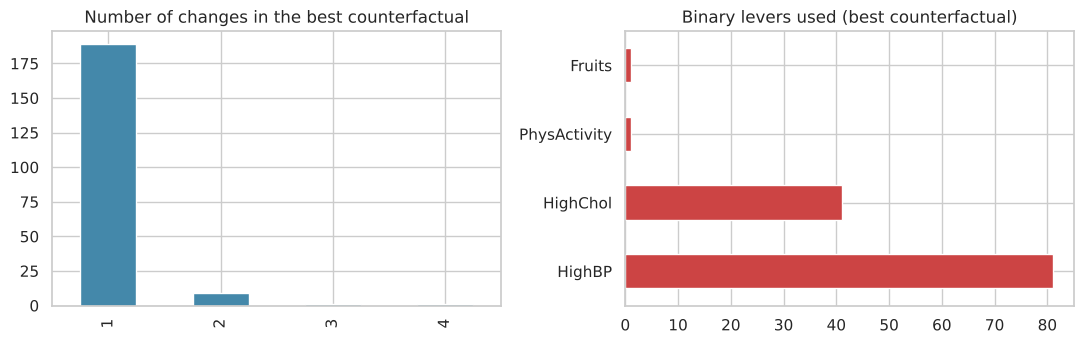

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
best.n_changed.value_counts().sort_index().plot.bar(ax=axes[0], color="#48a"); axes[0].set_title("Number of changes in the best counterfactual"); axes[0].set_xlabel("")
lever_counts.plot.barh(ax=axes[1], color="#c44"); axes[1].set_title("Binary levers used (best counterfactual)")
plt.tight_layout(); plt.savefig("../figures/local_counterfactuals.png", dpi=150); plt.show()